# Uniform Heisenberg chain: three Trotter-error estimates

開放境界の一様 Heisenberg 鎖

$$H=\sum_{j=1}^{N-1}(X_jX_{j+1}+Y_jY_{j+1}+Z_jZ_{j+1})=A+B$$

を even–odd の2層に分け、2次・4次 Suzuki 公式を比較する。$J=1$, $t=N$ とする。比較する量は次の3つ。

1. **naive $L_1$ bound** — fragment norm の和だけを使う finite-$r$ bound
2. **commutator bound** — nested commutator を使う finite-$r$ bound
3. **paper GS estimate** — leading BCH error operator の基底状態期待値を使う長時間漸近 estimate

3番目は finite-$r$ の rigorous bound ではなく state-specific estimate であり、前2者と metric scope が異なる。$N\le10$ では縮退を射影演算子で扱った $\|D_H(E_p)\|$ も診断用に計算する。理論は [Maxwell et al. (2026)](https://arxiv.org/html/2606.30738v1)、commutator bound は [Childs et al. (2021)](https://arxiv.org/html/1912.08854v3) に対応する。

## 1. Configuration

既定実行は $N\le40$。`RUN_LARGE_SYSTEMS=True` で $N=50,100,200$ を追加する。大規模点の paper GS estimate は MPO/DMRG を使う。

In [1]:
from pathlib import Path
import sys
import csv
import numpy as np
import matplotlib.pyplot as plt

HERE = Path.cwd()
if HERE.name != "practical_trotter_error_estimation" and (HERE / "practical_trotter_error_estimation").is_dir():
    HERE = HERE / "practical_trotter_error_estimation"
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))

import heisenberg_bounds as hb

RUN_LARGE_SYSTEMS = False
RUN_EXACT_ERROR = True
RUN_NONLINEAR_DEPHASING = True
N_DEFAULT = (4, 6, 8, 10, 12, 16, 20, 24, 32, 40)
N_LARGE = (50, 100, 200)
N_VALUES = N_DEFAULT + (N_LARGE if RUN_LARGE_SYSTEMS else ())
TARGET_EPSILON = 1e-3
ORDERS = (2, 4)

config = hb.ExperimentConfig(
    n_values=N_VALUES,
    orders=ORDERS,
    target_epsilon=TARGET_EPSILON,
)
(HERE / "results").mkdir(exist_ok=True)
(HERE / "figures").mkdir(exist_ok=True)
print(f"N={N_VALUES}; orders={ORDERS}; t=N; target epsilon={TARGET_EPSILON:g}")

N=(4, 6, 8, 10, 12, 16, 20, 24, 32, 40); orders=(2, 4); t=N; target epsilon=0.001


## 2. Definitions

すべての系列を $\epsilon(r)=C_p(N)/r^p$ の形で保持する。図の縦軸は target error などで正規化した比ではなく、この $\epsilon(r)$ の実値である。naive 系は Taylor bound、2次 commutator は Proposition 16、4次 commutator は Proposition 33 を使う。大規模系の交換子ノルムは Pauli coefficient $L_1$ で上から評価するため、追加の triangle inequality は入るが upper bound のままである。

論文法では

$$\log S_p(h)=-ihH+h^{p+1}R_{p+1}+\cdots,\qquad E_p=iR_{p+1}$$

を compact symmetric BCH で構成し、$C_p(N)=t^{p+1}|\langle\psi_0|E_p|\psi_0\rangle|$ とする。小規模の全状態量は、縮退を保った $D_H(E_p)=\sum_\lambda P_\lambda E_pP_\lambda$ から求める。

In [2]:
rows = hb.run_experiment(config)
csv_path = hb.save_results(rows, HERE / "results" / "heisenberg_bounds.csv")
print(f"saved {len(rows)} rows to {csv_path}")
print("\nN  p  method             coefficient        r       rigorous  scope")
for row in rows:
    if row.N in (10, 40):
        print(f"{row.N:2d} {row.order:2d} {row.method:18s} {row.coefficient:13.5e} "
              f"{row.r:8d} {str(row.rigorous):>10s}  {row.metric_scope}")

saved 68 rows to /Users/xisn/Documents/mizuta_RA/202609_quantum_algorithm/practical_trotter_error_estimation/results/heisenberg_bounds.csv

N  p  method             coefficient        r       rigorous  scope
10  2 naive_l1             2.95245e+07   171827       True  worst_case
10  2 commutator           8.80000e+04     9381       True  worst_case
10  2 paper_gs             8.96414e+03     2995      False  ground_state_asymptotic
10  2 paper_all_state      8.96414e+03     2995      False  all_state_asymptotic
10  4 naive_l1             1.19575e+15    33069       True  worst_case
10  4 commutator           3.60361e+08      775       True  worst_case
10  4 paper_gs             1.75700e+05      116      False  ground_state_asymptotic
10  4 paper_all_state      2.13811e+05      121      False  all_state_asymptotic
40  2 naive_l1             1.53755e+11 12399793       True  worst_case
40  2 commutator           2.86720e+07   169329       True  worst_case
40  2 paper_gs             2.70467e+

## 3. Error $\epsilon$ vs number of steps $r$

$N=10$ について、上段では ground-state error、下段では worst-case spectral error を比較する。naive $L_1$ と commutator はどちらにも有効な有限-$r$ の汎用上界、paper 系列は対応する scope の leading-BCH 漸近 estimate である。paper線の薄青帯はinverse-Liouvillian上界から得た有限時間dephasing補正範囲、青点線は $D_H(E_p)+Q_t(E_p)$ を直接使った有限時間leading-BCH estimateである。黒点も各パネルと同じ metric を dense unitary から実測する。

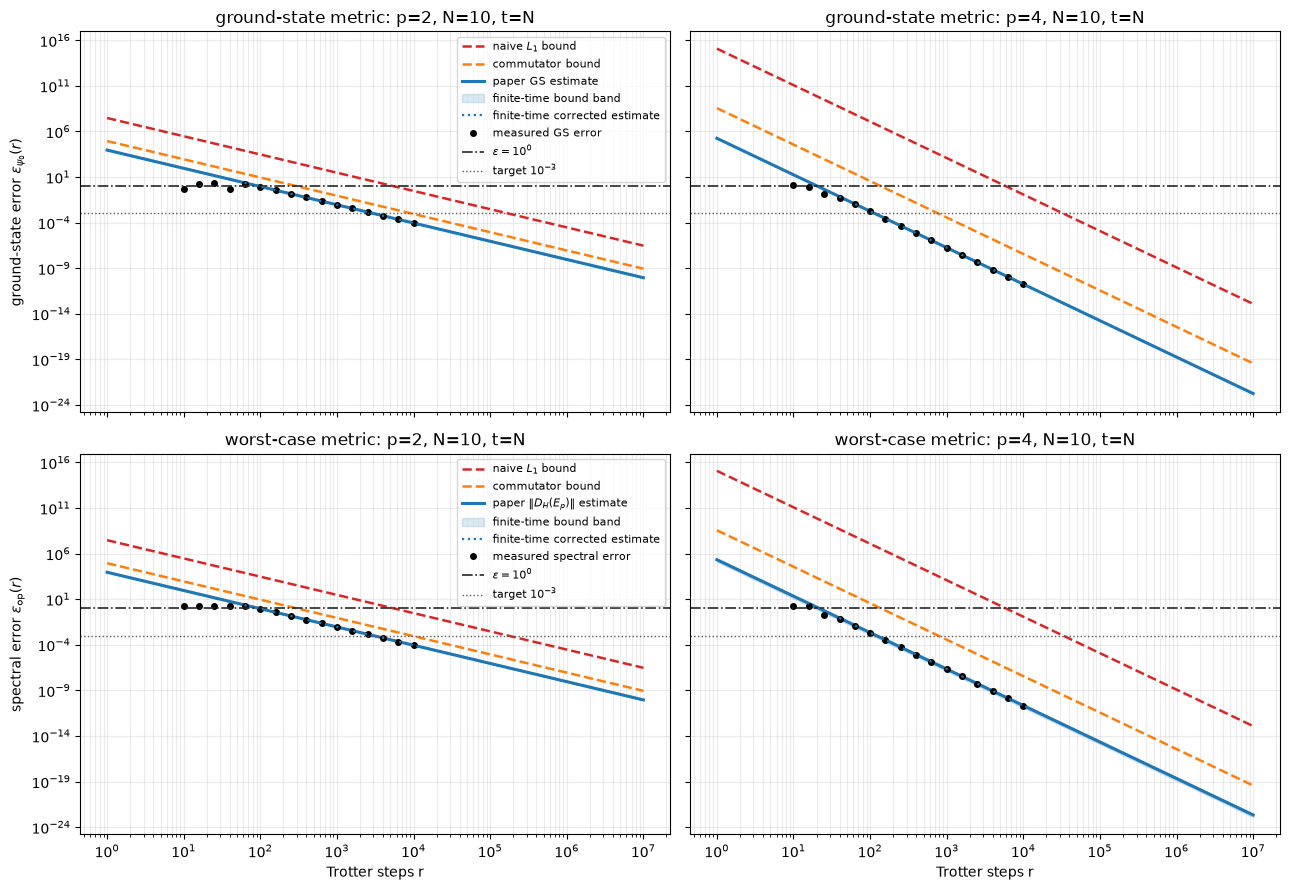

saved /Users/xisn/Documents/mizuta_RA/202609_quantum_algorithm/practical_trotter_error_estimation/figures/heisenberg_epsilon_vs_r.png


In [3]:
N_EPS_R = 10
r_values = np.unique(np.rint(np.logspace(0, 7, 180)).astype(int))
exact_r_values = np.unique(np.rint(np.logspace(1, 4, 16)).astype(int))
labels = {
    "naive_l1": r"naive $L_1$ bound",
    "commutator": "commutator bound",
    "paper_gs": "paper GS estimate",
}
colors = {"naive_l1": "C3", "commutator": "C1", "paper_gs": "C0"}

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey=True)
A_dense, B_dense, H_dense = hb.heisenberg_dense(N_EPS_R)
eps_dephasing_analyses = {}
eps_dephasing_bands = {}
for order in ORDERS:
    E_dense = hb.pauli_to_dense(hb.effective_error_pauli(N_EPS_R, order))
    analysis = hb.prepare_dephasing_analysis(H_dense, E_dense)
    eps_dephasing_analyses[(N_EPS_R, order)] = analysis
    averaged = hb.finite_time_average_operator(analysis, N_EPS_R)
    ground = analysis.eigenvectors[:, 0]
    for scope in ("ground", "operator"):
        metric = hb.dephasing_metric(analysis, N_EPS_R, scope)
        corrected = (np.linalg.norm(averaged @ ground) if scope == "ground"
                     else np.linalg.norm(averaged, ord=2))
        eps_dephasing_bands[(order, scope)] = (metric.diagonal_norm,
                                                   metric.inverse_gap_bound,
                                                   corrected)
ground_state = eps_dephasing_analyses[(N_EPS_R, 2)].eigenvectors[:, 0]
exact_unitary = None
if RUN_EXACT_ERROR:
    reference = eps_dephasing_analyses[(N_EPS_R, 2)]
    exact_unitary = ((reference.eigenvectors * np.exp(-1j * N_EPS_R * reference.energies))
                     @ reference.eigenvectors.conj().T)

for column, order in enumerate(ORDERS):
    ax_ground = axes[0, column]
    ax_worst = axes[1, column]
    for method in ("naive_l1", "commutator"):
        row = next(x for x in rows if x.N == N_EPS_R and x.order == order and x.method == method)
        values = hb.error_model(row.coefficient, r_values, order)
        for ax in (ax_ground, ax_worst):
            ax.loglog(r_values, values, color=colors[method], linestyle="--",
                      linewidth=1.8, label=labels[method])
    paper_gs = next(x for x in rows if x.N == N_EPS_R and x.order == order
                    and x.method == "paper_gs")
    ax_ground.loglog(r_values, hb.error_model(paper_gs.coefficient, r_values, order),
                       color="C0", linewidth=2.2, label="paper GS estimate")
    all_state = next(x for x in rows if x.N == N_EPS_R and x.order == order
                     and x.method == "paper_all_state")
    ax_worst.loglog(r_values, hb.error_model(all_state.coefficient, r_values, order),
                    color="C0", linewidth=2.2, label=r"paper $\|D_H(E_p)\|$ estimate")
    eta_values = float(N_EPS_R ** (order + 1)) / r_values.astype(float) ** order
    for ax, scope in ((ax_ground, "ground"), (ax_worst, "operator")):
        diagonal, correction_bound, corrected = eps_dephasing_bands[(order, scope)]
        lower = eta_values * max(0.0, diagonal - correction_bound)
        upper = eta_values * (diagonal + correction_bound)
        ax.fill_between(r_values, lower, upper, color="C0", alpha=0.16, zorder=1,
                        label="finite-time bound band")
        ax.loglog(r_values, eta_values * corrected, color="C0", linestyle=":",
                  linewidth=1.6, zorder=3, label="finite-time corrected estimate")
    if RUN_EXACT_ERROR:
        measured_ground = []
        measured_worst = []
        for r in exact_r_values:
            step = hb.suzuki_step_dense(A_dense, B_dense, N_EPS_R / int(r), order)
            approximate = np.linalg.matrix_power(step, int(r))
            difference = approximate - exact_unitary
            measured_ground.append(np.linalg.norm(difference @ ground_state))
            measured_worst.append(np.linalg.norm(difference, ord=2))
        ax_ground.loglog(exact_r_values, measured_ground, "ko", markersize=4,
                           label="measured GS error")
        ax_worst.loglog(exact_r_values, measured_worst, "ko", markersize=4,
                          label="measured spectral error")
    for ax in (ax_ground, ax_worst):
        ax.axhline(1.0, color="0.15", linestyle="-.", linewidth=1.2,
                   label=r"$\epsilon=10^0$")
        ax.axhline(TARGET_EPSILON, color="0.35", linestyle=":", linewidth=1,
                   label=r"target $10^{-3}$")
        ax.grid(True, which="both", alpha=0.25)
    ax_ground.set_title(f"ground-state metric: p={order}, N={N_EPS_R}, t=N")
    ax_worst.set_title(f"worst-case metric: p={order}, N={N_EPS_R}, t=N")
    ax_worst.set_xlabel("Trotter steps r")
axes[0, 0].set_ylabel(r"ground-state error $\epsilon_{\psi_0}(r)$")
axes[1, 0].set_ylabel(r"spectral error $\epsilon_{\mathrm{op}}(r)$")
axes[0, 0].legend(fontsize=8)
axes[1, 0].legend(fontsize=8)
fig.tight_layout()
eps_r_path = HERE / "figures" / "heisenberg_epsilon_vs_r.png"
fig.savefig(eps_r_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"saved {eps_r_path}")

## 4. Required steps $r$ vs system size $N$

目標精度 $\epsilon=10^{-3}$ に対して $r_*= (C_p/\epsilon)^{1/p}$ を計算する。図は実装に必要な $\lceil r_*\rceil$、fit は整数丸めによる staircase bias を避けるため $r_*$ を使う。paper GS系列の薄青帯は、ED可能な $N\le10$ だけで inverse-Liouvillian 上界を $r_*$ に伝播した範囲である。青点線は有限時間平均を直接使った補正値であり、帯も点線も $N>10$ へ外挿しない。

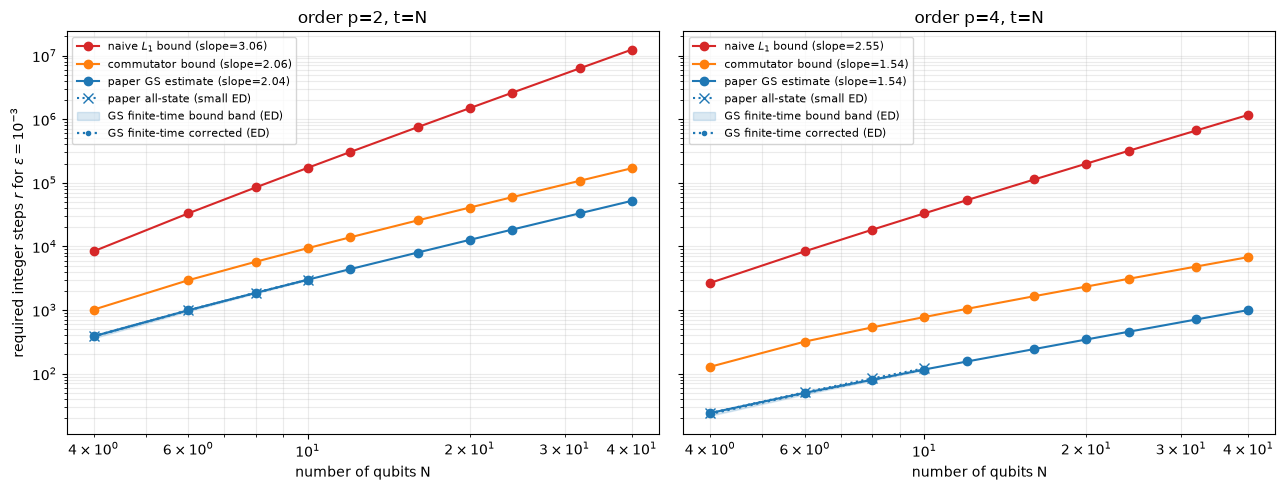

fitted r* ~ prefactor * N^alpha on the largest five default points:
p=2: naive_l1     alpha=3.0635, prefactor=153.8
p=2: commutator   alpha=2.0610, prefactor=84.76
p=2: paper_gs     alpha=2.0428, prefactor=27.82
p=4: naive_l1     alpha=2.5529, prefactor=95.33
p=4: commutator   alpha=1.5446, prefactor=22.83
p=4: paper_gs     alpha=1.5421, prefactor=3.382
saved /Users/xisn/Documents/mizuta_RA/202609_quantum_algorithm/practical_trotter_error_estimation/figures/heisenberg_r_vs_n.png and /Users/xisn/Documents/mizuta_RA/202609_quantum_algorithm/practical_trotter_error_estimation/results/heisenberg_scaling_exponents.csv


In [4]:
fit_rows = []
resource_band_n = (4, 6, 8, 10)
resource_band_analyses = dict(eps_dephasing_analyses)
for n_small in resource_band_n:
    missing_orders = [order for order in ORDERS
                      if (n_small, order) not in resource_band_analyses]
    if missing_orders:
        _, _, H_small = hb.heisenberg_dense(n_small)
        for order in missing_orders:
            E_small = hb.pauli_to_dense(hb.effective_error_pauli(n_small, order))
            resource_band_analyses[(n_small, order)] = (
                hb.prepare_dephasing_analysis(H_small, E_small))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, order in zip(axes, ORDERS):
    for method in hb.METHODS:
        part = sorted((x for x in rows if x.order == order and x.method == method),
                      key=lambda x: x.N)
        n = np.array([x.N for x in part], dtype=float)
        r_integer = np.array([x.r for x in part], dtype=float)
        r_continuous = np.array([x.r_continuous for x in part], dtype=float)
        fit_slice = slice(max(0, len(n) - 5), None)
        slope, intercept = np.polyfit(np.log(n[fit_slice]), np.log(r_continuous[fit_slice]), 1)
        fit_rows.append((order, method, slope, np.exp(intercept)))
        ax.loglog(n, r_integer, "o-", color=colors[method],
                  label=f"{labels[method]} (slope={slope:.2f})")
    diagnostic = sorted((x for x in rows if x.order == order
                         and x.method == "paper_all_state"), key=lambda x: x.N)
    ax.loglog([x.N for x in diagnostic], [x.r for x in diagnostic], "x:",
              color="C0", markersize=7, label="paper all-state (small ED)")
    band_lower, band_upper, corrected_steps = [], [], []
    for n_small in resource_band_n:
        analysis = resource_band_analyses[(n_small, order)]
        metric = hb.dephasing_metric(analysis, float(n_small), "ground")
        averaged = hb.finite_time_average_operator(analysis, float(n_small))
        ground = analysis.eigenvectors[:, 0]
        corrected = np.linalg.norm(averaged @ ground)
        coefficient_lower = n_small ** (order + 1) * max(
            0.0, metric.diagonal_norm - metric.inverse_gap_bound)
        coefficient_upper = n_small ** (order + 1) * (
            metric.diagonal_norm + metric.inverse_gap_bound)
        coefficient_corrected = n_small ** (order + 1) * corrected
        band_lower.append(hb.required_steps(
            coefficient_lower, TARGET_EPSILON, order)[0])
        band_upper.append(hb.required_steps(
            coefficient_upper, TARGET_EPSILON, order)[0])
        corrected_steps.append(hb.required_steps(
            coefficient_corrected, TARGET_EPSILON, order)[0])
    ax.fill_between(resource_band_n, band_lower, band_upper, color="C0",
                    alpha=0.16, zorder=1, label="GS finite-time bound band (ED)")
    ax.loglog(resource_band_n, corrected_steps, ".:", color="C0",
              linewidth=1.6, zorder=3, label="GS finite-time corrected (ED)")
    ax.set_title(f"order p={order}, t=N")
    ax.set_xlabel("number of qubits N")
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=8)
axes[0].set_ylabel(r"required integer steps $r$ for $\epsilon=10^{-3}$")
fig.tight_layout()
r_n_path = HERE / "figures" / "heisenberg_r_vs_n.png"
fig.savefig(r_n_path, dpi=180, bbox_inches="tight")
plt.show()

fit_path = HERE / "results" / "heisenberg_scaling_exponents.csv"
with fit_path.open("w", newline="", encoding="utf-8") as stream:
    writer = csv.writer(stream)
    writer.writerow(["order", "method", "N_exponent", "prefactor"])
    writer.writerows(fit_rows)
print("fitted r* ~ prefactor * N^alpha on the largest five default points:")
for order, method, slope, prefactor in fit_rows:
    print(f"p={order}: {method:12s} alpha={slope:.4f}, prefactor={prefactor:.4g}")
print(f"saved {r_n_path} and {fit_path}")

## 5. Finite-time dephasing correction

Theorem 1 の $D_H(E_p)$ 置換で有限時間に残る成分を

$$Q_t(E_p)=\frac1t\int_0^t e^{isH}E_pe^{-isH}\,ds-D_H(E_p)$$

とする。固有基底では異なるエネルギーblock間だけが残り、$(Q_t)_{mn}=(E_p)_{mn}e^{i\Delta_{mn}t/2}\operatorname{sinc}(\Delta_{mn}t/2)$ である。$X_{mn}=(E_p)_{mn}/(i\Delta_{mn})$ とおけば $\|Q_t\|\le2\|X\|/t$。これは行列要素を捨てる論文Appendix Aのminimum-gap boundより鋭い。縮退内は常にblockごと $D_H$ に含める。

以下ではGSとworst-caseを分離し、補正の対角主項に対する比を調べる。これはleading BCH operator $E_p$ 内の有限時間補正であり、より高次のBCH剰余を含む完全なfinite-$r$保証ではない。

In [5]:
DEPHASING_N_VALUES = (4, 6, 8, 10)
DEPHASING_TIME_VALUES = np.logspace(-1, 5, 31)
DEPHASING_SCOPES = ("ground", "operator")
analyses = dict(resource_band_analyses)
for n in DEPHASING_N_VALUES:
    missing_orders = [order for order in ORDERS if (n, order) not in analyses]
    if missing_orders:
        _, _, H = hb.heisenberg_dense(n)
        for order in missing_orders:
            E = hb.pauli_to_dense(hb.effective_error_pauli(n, order))
            analyses[(n, order)] = hb.prepare_dephasing_analysis(H, E)

record_map = {}
def add_dephasing_record(n, order, scope, time, nonlinear=False):
    analysis = analyses[(n, order)]
    metric = hb.dephasing_metric(analysis, time, scope)
    eta = TARGET_EPSILON / metric.diagonal_norm
    paper_bound = hb.paper_finite_time_residual_bound(analysis, time, eta, scope)
    nonlinear_value = ""
    if nonlinear and RUN_NONLINEAR_DEPHASING:
        nonlinear_value = hb.nonlinear_dephasing_residual(analysis, time, eta, scope)
    key = (n, order, scope, float(time))
    record_map[key] = {
        "N": n, "order": order, "scope": scope, "time": float(time),
        "gamma": metric.gamma, "diagonal_norm": metric.diagonal_norm,
        "residual": metric.residual,
        "relative_residual": metric.relative_residual,
        "inverse_gap_bound": metric.inverse_gap_bound,
        # Divide the Appendix-A unitary bound by eta so all three columns
        # have effective-error coefficient units.
        "minimum_gap_bound": paper_bound / eta,
        "eta": eta, "nonlinear_residual": nonlinear_value,
    }

for order in ORDERS:
    for scope in DEPHASING_SCOPES:
        for time in DEPHASING_TIME_VALUES:
            add_dephasing_record(10, order, scope, time)
for n in DEPHASING_N_VALUES:
    for order in ORDERS:
        for scope in DEPHASING_SCOPES:
            add_dephasing_record(n, order, scope, float(n), nonlinear=(n <= 8))

dephasing_records = list(record_map.values())
dephasing_path = HERE / "results" / "heisenberg_dephasing.csv"
dephasing_fields = ["N", "order", "scope", "time", "gamma",
                    "diagonal_norm", "residual", "relative_residual",
                    "inverse_gap_bound", "minimum_gap_bound", "eta",
                    "nonlinear_residual"]
with dephasing_path.open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=dephasing_fields)
    writer.writeheader()
    writer.writerows(dephasing_records)
print(f"saved {len(dephasing_records)} rows to {dephasing_path}")

saved 136 rows to /Users/xisn/Documents/mizuta_RA/202609_quantum_algorithm/practical_trotter_error_estimation/results/heisenberg_dephasing.csv


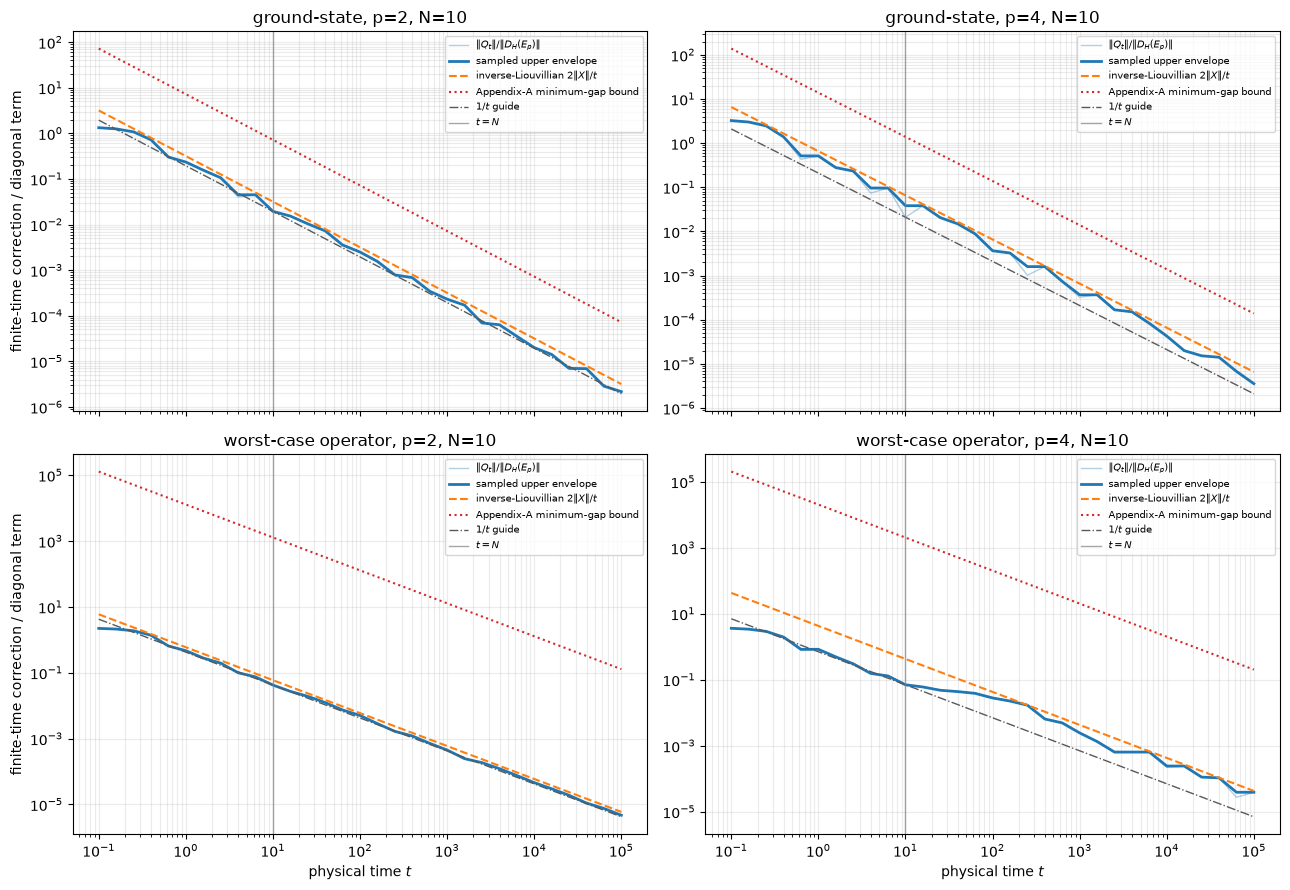

saved /Users/xisn/Documents/mizuta_RA/202609_quantum_algorithm/practical_trotter_error_estimation/figures/heisenberg_dephasing_vs_t.png


In [6]:
scope_labels = {"ground": "ground-state", "operator": "worst-case operator"}
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
for row_index, scope in enumerate(DEPHASING_SCOPES):
    for column, order in enumerate(ORDERS):
        ax = axes[row_index, column]
        part = sorted((x for x in dephasing_records if x["N"] == 10
                       and x["order"] == order and x["scope"] == scope),
                      key=lambda x: x["time"])
        times = np.array([x["time"] for x in part])
        actual = np.array([x["relative_residual"] for x in part])
        envelope = np.maximum.accumulate(actual[::-1])[::-1]
        inverse = np.array([x["inverse_gap_bound"] / x["diagonal_norm"] for x in part])
        minimum = np.array([x["minimum_gap_bound"] / x["diagonal_norm"] for x in part])
        anchor = actual[np.argmin(np.abs(times - 10.0))]
        ax.loglog(times, actual, color="C0", alpha=0.35, linewidth=1, label=r"$\|Q_t\|/\|D_H(E_p)\|$")
        ax.loglog(times, envelope, color="C0", linewidth=2, label="sampled upper envelope")
        ax.loglog(times, inverse, "--", color="C1", label=r"inverse-Liouvillian $2\|X\|/t$")
        ax.loglog(times, minimum, ":", color="C3", label="Appendix-A minimum-gap bound")
        ax.loglog(times, anchor * 10.0 / times, "-.", color="0.35", linewidth=1, label=r"$1/t$ guide")
        ax.axvline(10.0, color="0.5", linewidth=1, alpha=0.7, label=r"$t=N$")
        ax.set_title(f"{scope_labels[scope]}, p={order}, N=10")
        ax.grid(True, which="both", alpha=0.25)
        if row_index == 1:
            ax.set_xlabel(r"physical time $t$")
        if column == 0:
            ax.set_ylabel("finite-time correction / diagonal term")
        ax.legend(fontsize=7)
fig.tight_layout()
dephasing_t_path = HERE / "figures" / "heisenberg_dephasing_vs_t.png"
fig.savefig(dephasing_t_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"saved {dephasing_t_path}")

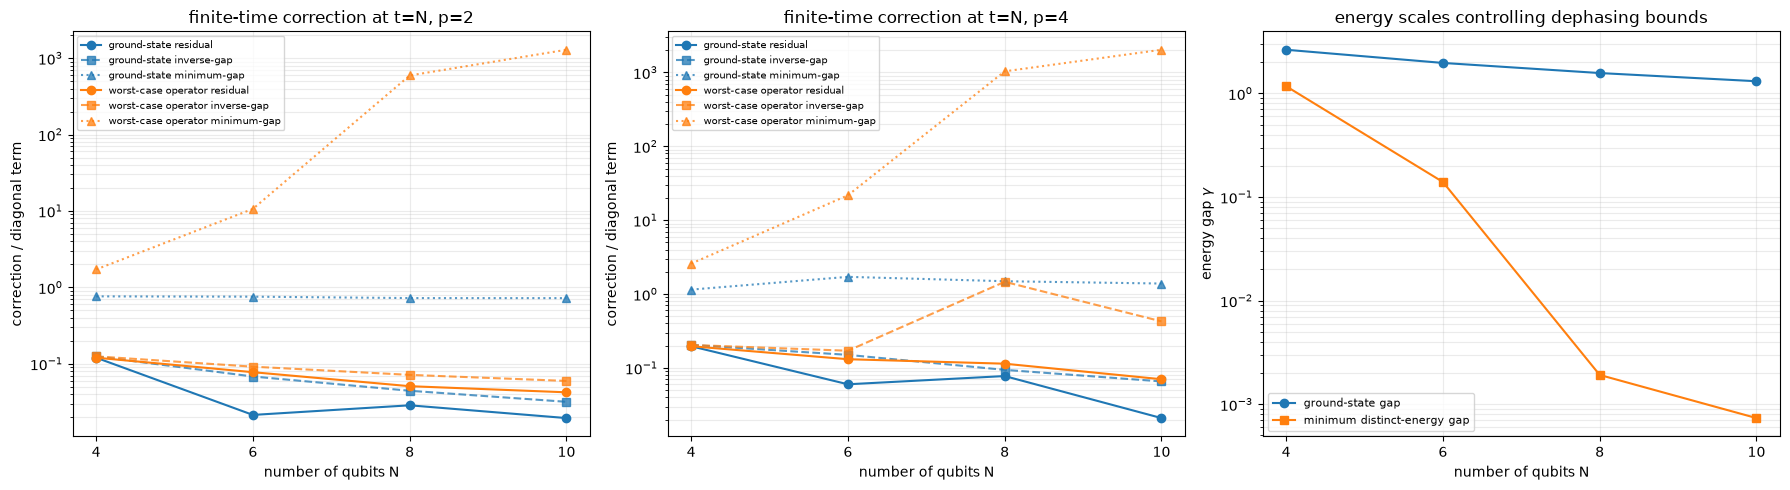

nonlinear residual / (eta * ||Q_t||) at target epsilon:
N= 4, p=2, ground  : 0.999784
N= 4, p=2, operator: 0.999784
N= 4, p=4, ground  : 1.000217
N= 4, p=4, operator: 1.000217
N= 6, p=2, ground  : 0.998436
N= 6, p=2, operator: 1.000171
N= 6, p=4, ground  : 1.001769
N= 6, p=4, operator: 1.000013
N= 8, p=2, ground  : 0.999933
N= 8, p=2, operator: 0.999852
N= 8, p=4, ground  : 0.999746
N= 8, p=4, operator: 0.999927
saved /Users/xisn/Documents/mizuta_RA/202609_quantum_algorithm/practical_trotter_error_estimation/figures/heisenberg_dephasing_vs_n.png


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
scope_colors = {"ground": "C0", "operator": "C1"}
for ax, order in zip(axes[:2], ORDERS):
    for scope in DEPHASING_SCOPES:
        part = sorted((x for x in dephasing_records if x["order"] == order
                       and x["scope"] == scope and np.isclose(x["time"], x["N"])),
                      key=lambda x: x["N"])
        n = np.array([x["N"] for x in part])
        actual = np.array([x["relative_residual"] for x in part])
        inverse = np.array([x["inverse_gap_bound"] / x["diagonal_norm"] for x in part])
        minimum = np.array([x["minimum_gap_bound"] / x["diagonal_norm"] for x in part])
        color = scope_colors[scope]
        ax.semilogy(n, actual, "o-", color=color, label=f"{scope_labels[scope]} residual")
        ax.semilogy(n, inverse, "s--", color=color, alpha=0.75, label=f"{scope_labels[scope]} inverse-gap")
        ax.semilogy(n, minimum, "^:", color=color, alpha=0.75, label=f"{scope_labels[scope]} minimum-gap")
    ax.set_title(f"finite-time correction at t=N, p={order}")
    ax.set_xlabel("number of qubits N")
    ax.set_ylabel("correction / diagonal term")
    ax.set_xticks(DEPHASING_N_VALUES)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=7)
ground_gaps = [analyses[(n, 2)].gamma_ground for n in DEPHASING_N_VALUES]
all_gaps = [analyses[(n, 2)].gamma_all for n in DEPHASING_N_VALUES]
axes[2].semilogy(DEPHASING_N_VALUES, ground_gaps, "o-", label="ground-state gap")
axes[2].semilogy(DEPHASING_N_VALUES, all_gaps, "s-", label="minimum distinct-energy gap")
axes[2].set_title("energy scales controlling dephasing bounds")
axes[2].set_xlabel("number of qubits N")
axes[2].set_ylabel(r"energy gap $\gamma$")
axes[2].set_xticks(DEPHASING_N_VALUES)
axes[2].grid(True, which="both", alpha=0.25)
axes[2].legend(fontsize=8)
fig.tight_layout()
dephasing_n_path = HERE / "figures" / "heisenberg_dephasing_vs_n.png"
fig.savefig(dephasing_n_path, dpi=180, bbox_inches="tight")
plt.show()

nonlinear_rows = [x for x in dephasing_records if x["nonlinear_residual"] != ""]
print("nonlinear residual / (eta * ||Q_t||) at target epsilon:")
for x in nonlinear_rows:
    ratio = x["nonlinear_residual"] / (x["eta"] * x["residual"])
    print(f"N={x['N']:2d}, p={x['order']}, {x['scope']:8s}: {ratio:.6f}")
print(f"saved {dephasing_n_path}")

## 6. Checks

ここでは Notebook の設定に直結する軽量チェックだけを行う。網羅的な検証は `python -m pytest practical_trotter_error_estimation/tests` に分離している。

In [8]:
A4, B4, H4 = hb.heisenberg_dense(4)
assert np.allclose(A4 + B4, H4)
assert np.allclose(H4, H4.conj().T)
for order in ORDERS:
    E = hb.pauli_to_dense(hb.effective_error_pauli(4, order))
    assert np.allclose(E, E.conj().T, atol=1e-10)
    naive = hb.naive_l1_coefficient(4, order)
    comm = hb.commutator_coefficient(4, order)
    for r in (1, 2, 4):
        measured = hb.trotter_error_dense(A4, B4, 4, r, order)
        assert measured <= hb.error_model(naive, r, order) + 1e-10
        assert measured <= hb.error_model(comm, r, order) + 1e-10
    analysis = hb.prepare_dephasing_analysis(H4, E)
    Q = hb.finite_time_dephasing_residual(analysis, 4.0)
    assert np.allclose(Q, Q.conj().T, atol=1e-10)
    for scope in ("ground", "operator"):
        metric = hb.dephasing_metric(analysis, 4.0, scope)
        assert metric.residual <= metric.inverse_gap_bound + 1e-10
print("Hamiltonian, Hermiticity, BCH, finite-r, and dephasing checks: OK")

Hamiltonian, Hermiticity, BCH, finite-r, and dephasing checks: OK


## 7. Interpretation

- naive $L_1$ と commutator は worst-case spectral-norm upper bound なので、上段の ground-state error に対しても有効だが状態固有には最適化されていない。後者は局所可換性を使うため大幅に小さい。
- $\epsilon_{\psi_0}(r)=\|(S_p^r-e^{-itH})|\psi_0\rangle\|_2$ の実測値と paper GS を上段で比較し、spectral-norm error と $\|D_H(E_p)\|$ を下段で比較する。
- paper GS は、基底状態に関係する leading BCH 成分だけを見る state-specific・long-time estimate。小さい値は回路全体の worst-case guarantee を意味しない。
- `paper all-state` は縮退固有空間を保つ $D_H(E_p)$ の診断で、任意に選ばれた固有ベクトルの対角成分だけを取る実装ではない。
- finite-time dephasing図の青線は、$D_H(E_p)$ だけを残すことで捨てた $Q_t(E_p)$ の大きさである。固定有限 $N$ では振動しながら $1/t$ envelopeで減衰する。
- 主要2図の薄青帯は $d=\|D_H(E_p)\|_{\rm scope}$ と $b=2\|X\|_{\rm scope}/t$ から作った $[\max(0,d-b),d+b]$ のleading-BCH範囲で、統計的error barではない。青点線は $D_H(E_p)+Q_t(E_p)$ を直接評価した有限時間補正値である。
- $r$ vs $N$ の帯は連続値 $r_*$ に補正範囲を伝播し、EDで評価した $N\le10$ で止めている。大規模$N$への帯の外挿は行っていない。
- minimum-gap boundは全スペクトルの非常に小さい準位差に支配される一方、inverse-Liouvillian boundは対応する行列要素も保持するため実測残差をよりよく反映する。
- 小規模の非線形チェックは、目標精度で $\eta\|Q_t\|$ が指数関数そのもののdephasing残差を再現することを検証する。ただしBCH高次剰余は別途残る。
- $r$ vs $N$ の3系列は、汎用的な保証と ground-state向けの実用estimateが要求リソースに与える差を示す比較であり、同じscopeの3種類のboundではない。凡例の fitted slope は各系列のresource scalingを示す。